# 라이브러리 임포트
##### 실습에 필요한 라이브러리를 임포트

In [33]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt   # 시각화
import seaborn as sns             # 시각화

from sklearn import set_config    #
set_config(display="text")

import warnings
warnings.filterwarnings('ignore')

## 데이터 불러오기(학습데이터, 테스트데이터)

In [34]:
train = pd.read_csv('data/csv/basketball_train.csv')
test = pd.read_csv('data/csv/basketball_test.csv')

print(train.head())
print(test.head())

          Player Pos   3P  TRB  BLK
0  Nicolas Batum  SG  1.8  6.2  0.4
1    Buddy Hield  SG  1.8  3.3  0.1
2    Robin Lopez   C  0.0  6.4  1.4
3   Nene Hilario   C  0.0  4.2  0.6
4  Alexis Ajinca   C  0.0  4.5  0.6
             Player Pos   3P  TRB  BLK
0  Montrezl Harrell   C  0.0  3.8  0.7
1   Jordan Clarkson  SG  1.4  3.0  0.1
2       Will Barton  SG  1.5  4.3  0.5
3     Mason Plumlee   C  0.0  7.5  1.1
4       Danny Green  SG  1.7  3.3  0.8


## SVM 최적의 파라미터 찾기

##### 1. C(cost, 비용) : 결정경계선의 마진을 결정하는 파라미터.
##### 2. gamma : 커널의 데이터포인트 표준 편차를 결정하는 조절 변수

In [35]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score


In [38]:
# sklearn에서 제공하는 GridSearchCV를 사용하면, 
# 손쉽게 최적의 C, gamma를 구할 수 있음.
# x : 학습 데이터, y : 학습 데이터 정답, nfolds = 나눌 폴드 개수 
def svc_param_selection(x, y, nfolds):
    svc_param = [
        {
            # 알고리즘 rbf ( 이차원 점으로 나타낼 수 있는 데이터를 무한한 차원으로 변환 )
            'kernel': ['rbf'],      
            # 감마값 
            'gamma': [0.00001, 0.0001, 0.001, 0.01, 0.1, 1],
            # 코스트 
            'C': [0.01, 0.1, 1, 10, 100, 1000]
        }
    ]

    clf = GridSearchCV(
        SVC(),     
        svc_param, 
        cv=nfolds
    )

    # 학습 요청
    clf.fit(x, y)

    print("최적 파라미터:", clf.best_params_)
    print("최고 평균 검증 정확도:", clf.best_score_)

    return clf

In [37]:
X_train = train[['3P', 'BLK']]
y_train = train[['Pos']]

# 10번 임의로 학습하도록 
clf = svc_param_selection(X_train, y_train.values.ravel(), 10)

최적 파라미터: {'C': 0.1, 'gamma': 1, 'kernel': 'rbf'}
최고 평균 검증 정확도: 0.95


## 시각화
##### 최적의 파라미터일 때의 결정경계선과, 다른 파라미터들일 때의 결정 경계선을 비교.

In [39]:
# 시각화를 하기 위해, 최적의 C와 최적의 C를 비교하기 위한 다른 C를 후보로 저장.
C_candidates = []
C_candidates.append(clf.best_params_['C'] * 0.01)
C_candidates.append(clf.best_params_['C'])
C_candidates.append(clf.best_params_['C'] * 100)


In [40]:
# 시각화를 하기 위해, 최적의 gamma와 최적의 gamma를 비교하기 위한 다른 C를 후보로 저장.
gamma_candidates = []
gamma_candidates.append(clf.best_params_['gamma'] * 0.01)
gamma_candidates.append(clf.best_params_['gamma'])
gamma_candidates.append(clf.best_params_['gamma'] * 100)

In [41]:
X = train[['3P', 'BLK']]
Y = train['Pos'].tolist()



In [42]:
# 포지션에 해당하는 문자열 SG와 C를 벡터화합니다.
position = []

for i in Y:
  # 센터
  if i == 'C':
    position.append(0)
  # 슈팅가드
  else:
    position.append(1)
        
# 각각의 파라미터에 해당하는 SVM 모델을 만들어 classifiers에 저장.
classifiers = []

for C in C_candidates:
  for gamma in gamma_candidates:
    clf = SVC(C=C, gamma=gamma)
    clf.fit(X, Y)
    classifiers.append((C, gamma, clf))

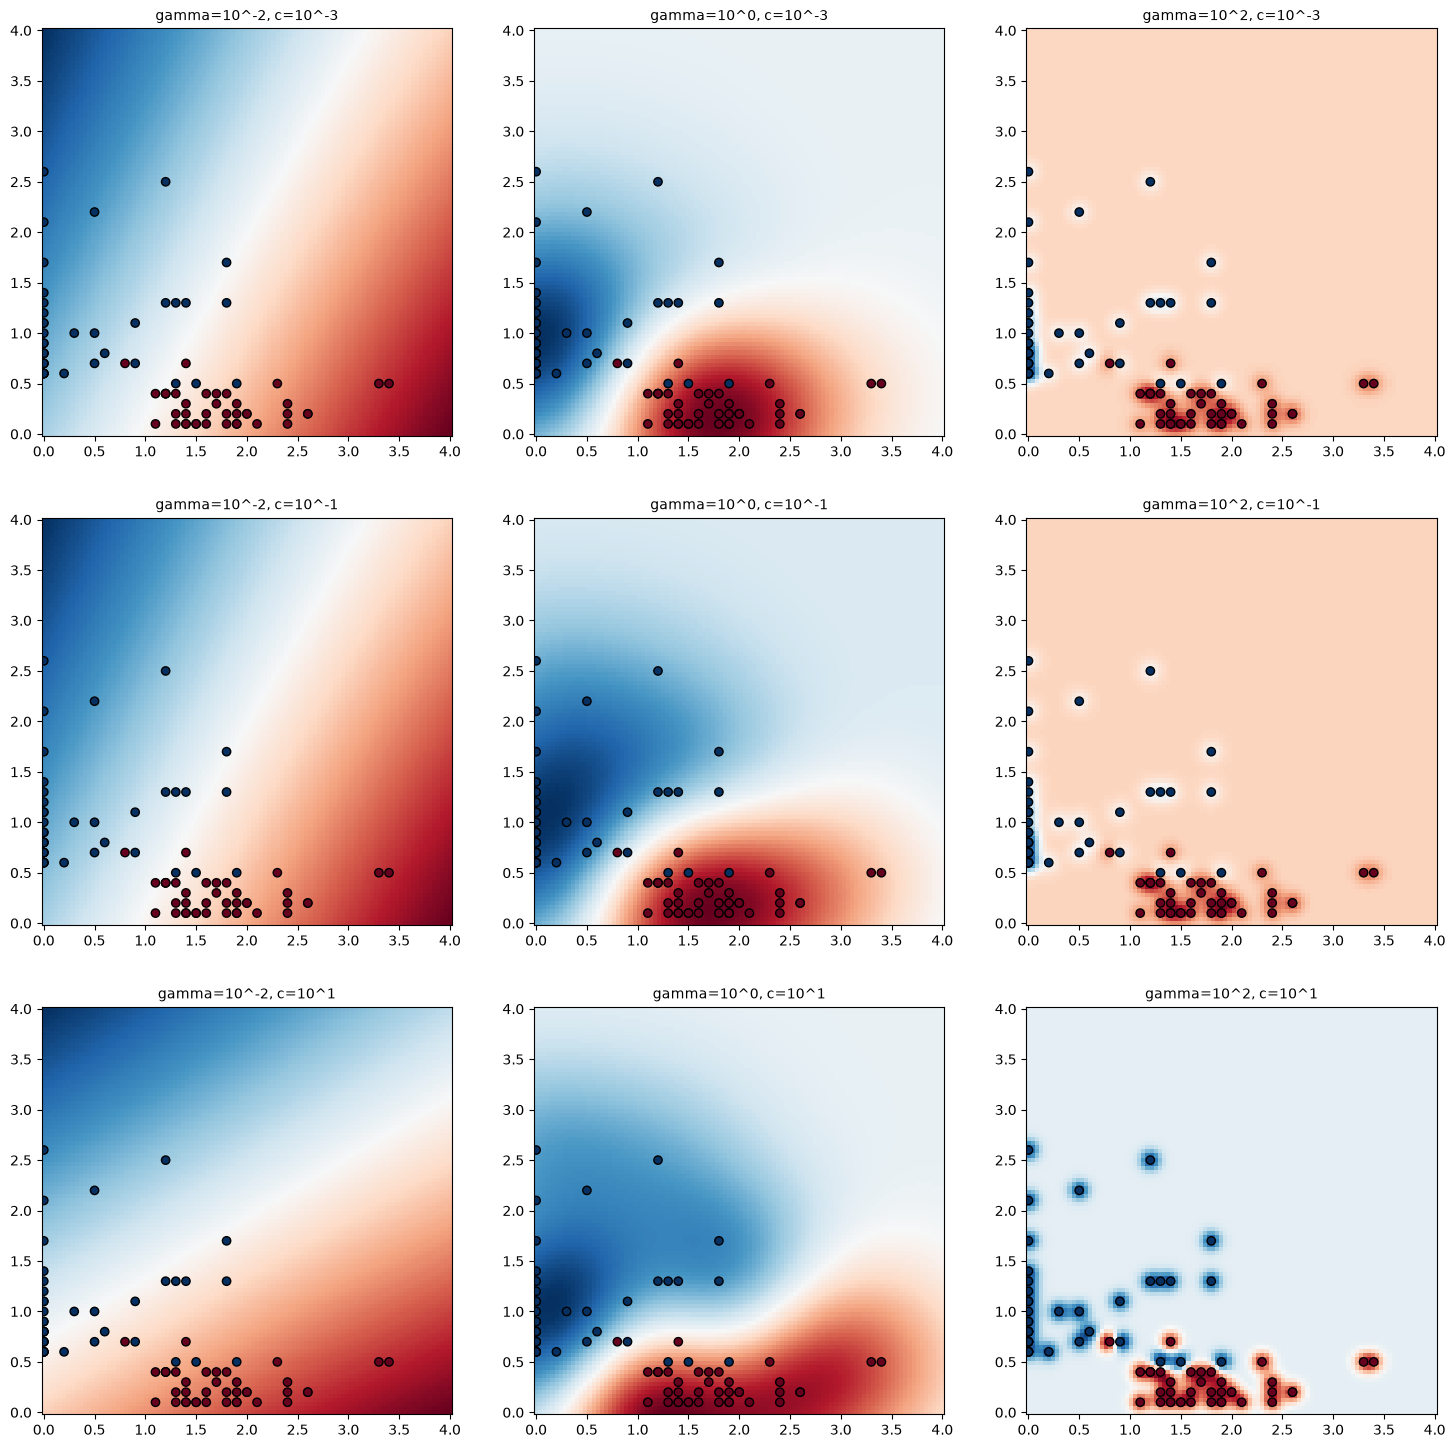

In [45]:
# 18,18 사이즈의 차트를 구성합니다.
plt.figure(figsize=(18,18))

# 100 * 100 좌표 생성 ( 0~4, 사이값 개수 100 )
xx, yy = np.meshgrid(
  np.linspace(0, 4, 100),       # 0 ~ 4 까지 균등한 간격의 100 개 데이터를 생성          
  np.linspace(0, 4, 100)        # 0 ~ 4 까지 균등한 간격의 100 개 데이터를 생성          
)

# 각각의 모델들에 대한 결정 경계 함수를 적용하여 함께 시각화합니다.
for (k, (C, gamma, clf))  in enumerate(classifiers):  
  # 위치 조정
  Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])      # np.c_ -> [1, 2, 3] [4, 5, 6] -> [1,4], [2,5], [3,6]   
  Z = Z.reshape(xx.shape)

  # 최적의 모델을 포함한 다른 파라미터로 학습된 모델들을 함께 시각화해봅니다.
  plt.subplot(
    len(C_candidates),
    len(gamma_candidates),
    k+1                         # 야는 1부터 시작 k는 0부터 시작 해서 +1
  )

  plt.title("gamma=10^%d, c=10^%d" % (np.log10(gamma), np.log10(C)), size='medium')

  plt.pcolormesh(xx, yy, -Z, cmap=plt.cm.RdBu)        # Z 부호를 바꾼 이유는?? 

  # 산점도 모양으로 출력 
  plt.scatter(X['3P'], X['BLK'], c=position, cmap=plt.cm.RdBu_r, edgecolors='k')


## 테스트
##### sklearn의 gridsearchcv로 얻어진 최적의 파라미터로 학습된 clf를 이용하여, 테스트를 진행

In [ ]:
# 테스트에 사용될 특징을 지정



In [ ]:
comparison = pd.DataFrame({'예측값':, '정답':})
comparison

In [ ]:
# check accuracy
print('accuracy : ' + str())